# PA3 — Parte 1A: SimCLR na GPU do Kaggle

Este notebook contém os scripts completos. Não precisa enviar arquivos `.py`.

1. Envie a pasta **pa3_dados completa** como Dataset privado no Kaggle e adicione-a em **Add Input**.
   Ela precisa conter `classes.csv`, `labels/` e `images/{train,val,test_public}/`.
   Extraia arquivos ZIP antes de criar o Dataset.
2. Em **Settings / Accelerator**, selecione uma GPU e habilite **Internet** para baixar os pesos ImageNet.
3. Execute as células em ordem. A configuração padrão é 224px, batch 64, 100 épocas SimCLR,
   100 de avaliação linear e 30 de fine-tuning, para as duas políticas de crop.
4. Baixe os resultados em `/kaggle/working`. Use **Save Version** para preservar os outputs.

O código usa uma GPU, mesmo quando duas estão disponíveis. O teste público é usado para relato;
os checkpoints e a política de crop são escolhidos pelo F1 macro de validação.

Documentação da plataforma: https://www.kaggle.com/docs/notebooks


In [7]:
from pathlib import Path
import os, sys, json, shutil, subprocess, time
import torch, torchvision
import numpy, sklearn, matplotlib, PIL
print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)
assert torch.cuda.is_available(), "Ative GPU em Settings / Accelerator antes de continuar."
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
WORK = Path('/kaggle/working/pa3')
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)


PyTorch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
GPU: Tesla T4
VRAM (GB): 14.6


## Dados e configuração

A detecção é automática quando há uma única pasta válida. Caso encontre mais de uma,
preencha `DATA_DIR_OVERRIDE`. Para retomar em outra sessão, anexe os outputs salvos da sessão
anterior e indique em `RESTORE_FROM` a pasta `trilha_a_completa` correspondente.
Não altere batch, resolução ou épocas ao retomar. Checkpoints parciais são salvos ao final de cada época;
o trabalho da época interrompida será repetido. A avaliação linear e o fine-tuning reiniciam se interrompidos.


In [8]:
DATA_DIR_OVERRIDE = None  # Ex.: '/kaggle/input/meu-dataset/pa3_dados'
RESTORE_FROM = None      # Ex.: '/kaggle/input/outputs-anteriores/pa3/resultados/trilha_a_completa'
IMAGE_SIZE = 224
BATCH_SIZE = 64
SSL_EPOCHS = 100
LINEAR_EPOCHS = 100
FINETUNE_EPOCHS = 30
WORKERS = 2  # Use 0 se ocorrer erro de multiprocessing.
SEED = 42

input_root = Path('/kaggle/input')
candidates = sorted({p.parent for p in input_root.rglob('classes.csv')
    if (p.parent / 'labels/rotulos_5.csv').is_file()
    and (p.parent / 'images/train').is_dir()})
if DATA_DIR_OVERRIDE:
    DATA_DIR = Path(DATA_DIR_OVERRIDE)
else:
    assert len(candidates) == 1, f'Preencha DATA_DIR_OVERRIDE. Pastas encontradas: {candidates}'
    DATA_DIR = candidates[0]
for relative in ['classes.csv', 'labels/rotulos_5.csv', 'labels/val.csv', 'labels/test_public.csv',
                 'images/train', 'images/val', 'images/test_public']:
    assert (DATA_DIR / relative).exists(), f'Arquivo/pasta ausente: {relative}'
train_count = sum(p.suffix.lower() == '.jpg' for p in (DATA_DIR / 'images/train').iterdir())
assert train_count == 6505, f'Esperadas 6505 imagens de treino; encontradas {train_count}'
OUTPUT = WORK / 'resultados/trilha_a_completa'
if RESTORE_FROM:
    source = Path(RESTORE_FROM)
    assert source.is_dir() and source.resolve() != OUTPUT.resolve()
    shutil.copytree(source, OUTPUT, dirs_exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Dados:', DATA_DIR, '\nResultados:', OUTPUT, '\nImagens train:', train_count)


Dados: /kaggle/input/datasets/mariaeduardamesquita/pa3-dados/pa3_dados 
Resultados: /kaggle/working/pa3/resultados/trilha_a_completa 
Imagens train: 6505


## Scripts incorporados e métricas da Parte 0
Os resultados locais da Parte 0 são incluídos para referência, sem refazer esses treinos.


In [9]:
SCRIPTS = {'part0.py': '"""Supervised baselines for Part 0 of the PA3 assignment."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport json\nimport random\nfrom pathlib import Path\nfrom typing import Any\n\nimport matplotlib\n\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport torch\nfrom PIL import Image, ImageOps\nfrom sklearn.metrics import accuracy_score, confusion_matrix, f1_score\nfrom torch import nn\nfrom torch.utils.data import DataLoader, Dataset\n\n\nMEAN = (0.485, 0.456, 0.406)\nSTD = (0.229, 0.224, 0.225)\n\n\ndef load_classes(classes_csv: Path) -> list[str]:\n    with classes_csv.open(encoding="utf-8-sig", newline="") as file:\n        rows = list(csv.DictReader(file))\n    if not rows or not {"idx", "label"}.issubset(rows[0]):\n        raise ValueError(f"{classes_csv} deve conter as colunas idx,label.")\n    rows.sort(key=lambda row: int(row["idx"]))\n    indices = [int(row["idx"]) for row in rows]\n    if indices != list(range(len(rows))):\n        raise ValueError(f"Os índices em {classes_csv} devem começar em zero e ser contíguos.")\n    return [row["label"] for row in rows]\n\n\ndef read_labels(labels_csv: Path, class_names: list[str]) -> list[tuple[str, int]]:\n    name_to_index = {name: index for index, name in enumerate(class_names)}\n    with labels_csv.open(encoding="utf-8-sig", newline="") as file:\n        reader = csv.DictReader(file)\n        if not {"image_id", "label"}.issubset(reader.fieldnames or []):\n            raise ValueError(f"{labels_csv} deve conter as colunas image_id,label.")\n        rows: list[tuple[str, int]] = []\n        seen_ids: set[str] = set()\n        for line, row in enumerate(reader, start=2):\n            image_id = row["image_id"].strip()\n            raw_label = row["label"].strip()\n            if not image_id or not raw_label:\n                raise ValueError(f"ID ou rótulo vazio em {labels_csv}, linha {line}.")\n            if image_id in seen_ids:\n                raise ValueError(f"ID duplicado {image_id!r} em {labels_csv}.")\n            seen_ids.add(image_id)\n            if image_id.lower().endswith(".jpg"):\n                image_id = image_id[:-4]\n            try:\n                label_index = int(raw_label)\n            except ValueError:\n                if raw_label not in name_to_index:\n                    raise ValueError(f"Classe desconhecida {raw_label!r} em {labels_csv}, linha {line}.")\n                label_index = name_to_index[raw_label]\n            if not 0 <= label_index < len(class_names):\n                raise ValueError(f"Índice de classe inválido {label_index} em {labels_csv}, linha {line}.")\n            rows.append((image_id, label_index))\n    if not rows:\n        raise ValueError(f"Nenhum exemplo encontrado em {labels_csv}.")\n    return rows\n\n\nclass CameraTrapDataset(Dataset[tuple[torch.Tensor, int]]):\n    def __init__(self, images_dir: Path, labels_csv: Path, class_names: list[str], image_size: int):\n        self.images_dir = images_dir\n        self.rows = read_labels(labels_csv, class_names)\n        self.image_size = image_size\n        self.mean = torch.tensor(MEAN, dtype=torch.float32).view(3, 1, 1)\n        self.std = torch.tensor(STD, dtype=torch.float32).view(3, 1, 1)\n        missing = [\n            image_id\n            for image_id, _ in self.rows\n            if not (images_dir / f"{image_id}.jpg").is_file()\n        ]\n        if missing:\n            sample = ", ".join(missing[:5])\n            raise FileNotFoundError(\n                f"{len(missing)} imagens referenciadas por {labels_csv} não estão em "\n                f"{images_dir}; exemplos: {sample}"\n            )\n\n    def __len__(self) -> int:\n        return len(self.rows)\n\n    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:\n        image_id, label = self.rows[index]\n        with Image.open(self.images_dir / f"{image_id}.jpg") as source:\n            image = ImageOps.pad(\n                source.convert("RGB"),\n                (self.image_size, self.image_size),\n                method=Image.Resampling.BILINEAR,\n            )\n        array = np.asarray(image, dtype=np.float32) / 255.0\n        tensor = torch.from_numpy(array).permute(2, 0, 1)\n        return (tensor - self.mean) / self.std, label\n\n\nclass SmallCNN(nn.Module):\n    """A compact CNN trained from random initialization."""\n\n    def __init__(self, num_classes: int):\n        super().__init__()\n        self.features = nn.Sequential(\n            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),\n            nn.BatchNorm2d(32),\n            nn.ReLU(inplace=True),\n            nn.MaxPool2d(2),\n            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),\n            nn.BatchNorm2d(64),\n            nn.ReLU(inplace=True),\n            nn.MaxPool2d(2),\n            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),\n            nn.BatchNorm2d(128),\n            nn.ReLU(inplace=True),\n            nn.AdaptiveAvgPool2d(1),\n        )\n        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, num_classes))\n\n    def forward(self, images: torch.Tensor) -> torch.Tensor:\n        return self.classifier(self.features(images))\n\n\ndef make_model(model_name: str, num_classes: int) -> nn.Module:\n    if model_name == "small_cnn":\n        return SmallCNN(num_classes)\n    if model_name == "resnet18":\n        try:\n            from torchvision.models import ResNet18_Weights, resnet18\n        except ImportError as error:\n            raise RuntimeError(\n                "A versão ResNet-18 requer torchvision. Instale as dependências com "\n                "`python -m pip install -r requirements.txt`."\n            ) from error\n        model = resnet18(weights=ResNet18_Weights.DEFAULT)\n        model.fc = nn.Linear(model.fc.in_features, num_classes)\n        return model\n    raise ValueError(f"Modelo desconhecido: {model_name}")\n\n\ndef evaluate(\n    model: nn.Module, loader: DataLoader[tuple[torch.Tensor, int]], device: torch.device\n) -> tuple[float, float, float, list[int], list[int]]:\n    criterion = nn.CrossEntropyLoss()\n    model.eval()\n    total_loss = 0.0\n    actual: list[int] = []\n    predicted: list[int] = []\n    with torch.inference_mode():\n        for images, labels in loader:\n            images = images.to(device)\n            labels = labels.to(device)\n            logits = model(images)\n            total_loss += criterion(logits, labels).item() * labels.size(0)\n            actual.extend(labels.cpu().tolist())\n            predicted.extend(logits.argmax(dim=1).cpu().tolist())\n    return (\n        total_loss / len(loader.dataset),\n        f1_score(actual, predicted, average="macro", zero_division=0),\n        accuracy_score(actual, predicted),\n        actual,\n        predicted,\n    )\n\n\ndef write_history_plot(history: dict[str, list[float]], path: Path) -> None:\n    epochs = range(1, len(history["train_loss"]) + 1)\n    figure, axes = plt.subplots(1, 2, figsize=(11, 4))\n    axes[0].plot(epochs, history["train_loss"], label="Treino")\n    axes[0].plot(epochs, history["val_loss"], label="Validação")\n    axes[0].set(title="Perda", xlabel="Época", ylabel="Cross-entropy")\n    axes[1].plot(epochs, history["train_macro_f1"], label="Treino")\n    axes[1].plot(epochs, history["val_macro_f1"], label="Validação")\n    axes[1].set(title="F1 macro", xlabel="Época", ylabel="F1 macro")\n    for axis in axes:\n        axis.legend()\n        axis.grid(alpha=0.25)\n    figure.tight_layout()\n    figure.savefig(path, dpi=160)\n    plt.close(figure)\n\n\ndef train_model(\n    model_name: str,\n    datasets: dict[str, CameraTrapDataset],\n    class_names: list[str],\n    output_dir: Path,\n    epochs: int,\n    batch_size: int,\n    image_size: int,\n    seed: int,\n) -> dict[str, Any]:\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    model = make_model(model_name, len(class_names)).to(device)\n    if model_name == "resnet18":\n        learning_rate = 1e-4\n    else:\n        learning_rate = 1e-3\n    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)\n    criterion = nn.CrossEntropyLoss()\n    loaders = {\n        split: DataLoader(\n            dataset,\n            batch_size=batch_size,\n            shuffle=(split == "train"),\n            num_workers=0,\n            pin_memory=device.type == "cuda",\n        )\n        for split, dataset in datasets.items()\n    }\n    output_dir.mkdir(parents=True, exist_ok=True)\n    history: dict[str, list[float]] = {\n        "train_loss": [],\n        "val_loss": [],\n        "train_macro_f1": [],\n        "val_macro_f1": [],\n    }\n    best_f1 = -1.0\n    best_val_loss = float("inf")\n    best_checkpoint = output_dir / "best.pt"\n\n    for epoch in range(1, epochs + 1):\n        model.train()\n        for images, labels in loaders["train"]:\n            images = images.to(device)\n            labels = labels.to(device)\n            optimizer.zero_grad(set_to_none=True)\n            loss = criterion(model(images), labels)\n            loss.backward()\n            optimizer.step()\n\n        train_loss, train_f1, _, _, _ = evaluate(model, loaders["train"], device)\n        val_loss, val_f1, _, _, _ = evaluate(model, loaders["val"], device)\n        history["train_loss"].append(train_loss)\n        history["val_loss"].append(val_loss)\n        history["train_macro_f1"].append(train_f1)\n        history["val_macro_f1"].append(val_f1)\n        print(\n            f"{model_name} época {epoch:03d}/{epochs} | "\n            f"perda treino/val={train_loss:.4f}/{val_loss:.4f} | "\n            f"F1 macro treino/val={train_f1:.4f}/{val_f1:.4f}"\n        )\n        if val_f1 > best_f1 or (val_f1 == best_f1 and val_loss < best_val_loss):\n            best_f1 = val_f1\n            best_val_loss = val_loss\n            torch.save(\n                {\n                    "model_name": model_name,\n                    "model_state_dict": model.state_dict(),\n                    "class_names": class_names,\n                    "image_size": image_size,\n                    "mean": MEAN,\n                    "std": STD,\n                    "seed": seed,\n                    "best_epoch": epoch,\n                },\n                best_checkpoint,\n            )\n\n    with (output_dir / "history.json").open("w", encoding="utf-8") as file:\n        json.dump(history, file, indent=2)\n    if model_name == "resnet18":\n        write_history_plot(history, output_dir / "curva_treino_validacao.png")\n\n    checkpoint = torch.load(best_checkpoint, map_location=device, weights_only=True)\n    model.load_state_dict(checkpoint["model_state_dict"])\n    test_loss, test_f1, test_accuracy, actual, predicted = evaluate(\n        model, loaders["test_public"], device\n    )\n    metrics = {\n        "model": model_name,\n        "best_epoch": checkpoint["best_epoch"],\n        "test_public_macro_f1": test_f1,\n        "test_public_accuracy": test_accuracy,\n        "test_public_loss": test_loss,\n        "parameter_count": sum(parameter.numel() for parameter in model.parameters()),\n        "num_test_public": len(actual),\n        "class_names": class_names,\n    }\n    with (output_dir / "test_public_metrics.json").open("w", encoding="utf-8") as file:\n        json.dump(metrics, file, indent=2)\n    print(\n        f"{model_name} | melhor época pelo val: {checkpoint[\'best_epoch\']} | "\n        f"F1 macro test_public={test_f1:.4f} | acurácia test_public={test_accuracy:.4f}"\n    )\n    if model_name == "resnet18":\n        matrix = confusion_matrix(actual, predicted, labels=list(range(len(class_names))))\n        with (output_dir / "matriz_confusao.csv").open(\n            "w", encoding="utf-8", newline=""\n        ) as file:\n            writer = csv.writer(file)\n            writer.writerow(["classe", *class_names])\n            writer.writerows(\n                [class_names[index], *row.tolist()] for index, row in enumerate(matrix)\n            )\n        figure, axis = plt.subplots(figsize=(12, 10))\n        image = axis.imshow(matrix, cmap="Blues")\n        axis.set(\n            xticks=range(len(class_names)),\n            yticks=range(len(class_names)),\n            xticklabels=class_names,\n            yticklabels=class_names,\n            xlabel="Classe prevista",\n            ylabel="Classe real",\n            title="ResNet-18 — matriz de confusão no test_public",\n        )\n        plt.setp(axis.get_xticklabels(), rotation=60, ha="right", rotation_mode="anchor")\n        figure.colorbar(image, ax=axis)\n        figure.tight_layout()\n        figure.savefig(output_dir / "matriz_confusao.png", dpi=160)\n        plt.close(figure)\n    return metrics\n\n\ndef parse_args() -> argparse.Namespace:\n    parser = argparse.ArgumentParser(\n        description="Treina as duas baselines supervisionadas da Parte 0."\n    )\n    parser.add_argument("--data-dir", type=Path, default=Path("pa3_dados"))\n    parser.add_argument("--output-dir", type=Path, default=Path("resultados/parte0"))\n    parser.add_argument("--epochs", type=int, default=30)\n    parser.add_argument("--batch-size", type=int, default=16)\n    parser.add_argument("--image-size", type=int, default=224)\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument(\n        "--model",\n        choices=("both", "small_cnn", "resnet18"),\n        default="both",\n        help="Permite executar uma versão individual ou as duas em sequência.",\n    )\n    args = parser.parse_args()\n    if args.epochs < 1 or args.batch_size < 1 or args.image_size < 32:\n        parser.error("--epochs e --batch-size devem ser positivos; --image-size deve ser >= 32.")\n    return args\n\n\ndef main() -> None:\n    args = parse_args()\n    data_dir: Path = args.data_dir\n    classes = load_classes(data_dir / "classes.csv")\n    split_files = {\n        "train": (data_dir / "images" / "train", data_dir / "labels" / "rotulos_5.csv"),\n        "val": (data_dir / "images" / "val", data_dir / "labels" / "val.csv"),\n        "test_public": (\n            data_dir / "images" / "test_public",\n            data_dir / "labels" / "test_public.csv",\n        ),\n    }\n    missing = [str(labels) for _, labels in split_files.values() if not labels.is_file()]\n    missing.extend(str(images) for images, _ in split_files.values() if not images.is_dir())\n    if missing:\n        raise FileNotFoundError(\n            "Dados necessários ausentes: "\n            + ", ".join(missing)\n            + ". Extraia o pacote completo pa3_dados, incluindo labels/ e images/val."\n        )\n    datasets = {\n        split: CameraTrapDataset(images, labels, classes, args.image_size)\n        for split, (images, labels) in split_files.items()\n    }\n    if len(datasets["train"]) != 105:\n        raise ValueError(\n            f"A Parte 0 requer os 105 exemplos de rotulos_5.csv; "\n            f"foram encontrados {len(datasets[\'train\'])}."\n        )\n    if len(datasets["val"]) != 202:\n        print(f"Aviso: o val tem {len(datasets[\'val\'])} exemplos (o pacote informa 202).")\n    model_names = ("small_cnn", "resnet18") if args.model == "both" else (args.model,)\n    results = []\n    for model_name in model_names:\n        results.append(\n            train_model(\n                model_name,\n                datasets,\n                classes,\n                args.output_dir / model_name,\n                args.epochs,\n                args.batch_size,\n                args.image_size,\n                args.seed,\n            )\n        )\n    with (args.output_dir / "resumo_test_public.json").open("w", encoding="utf-8") as file:\n        json.dump(results, file, indent=2)\n\n\nif __name__ == "__main__":\n    main()\n', 'part1a.py': '"""SimCLR experiments for Part 1, Track A of the PA3 assignment."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport json\nimport random\nfrom pathlib import Path\nfrom typing import Any, Callable\n\nimport matplotlib\n\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport torch\nfrom PIL import Image\nfrom sklearn.metrics import accuracy_score, f1_score\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom torch.utils.data import DataLoader, Dataset, TensorDataset\n\nfrom part0 import CameraTrapDataset, load_classes\n\n\nEXPECTED_UNLABELED_IMAGES = 6505\nAUGMENTATION_SCALES = {\n    "standard": (0.08, 1.0),\n    "context_preserving": (0.5, 1.0),\n}\n\n\ndef seed_everything(seed: int) -> None:\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef make_resnet18(pretrained: bool) -> nn.Module:\n    try:\n        from torchvision.models import ResNet18_Weights, resnet18\n    except ImportError as error:\n        raise RuntimeError(\n            "A Trilha A requer torchvision. Instale as dependências com "\n            "`python -m pip install -r requirements.txt`."\n        ) from error\n    weights = ResNet18_Weights.DEFAULT if pretrained else None\n    model = resnet18(weights=weights)\n    model.fc = nn.Identity()\n    return model\n\n\ndef make_augmentations(\n    image_size: int, crop_scale: tuple[float, float]\n) -> Callable[[Image.Image], torch.Tensor]:\n    try:\n        from torchvision import transforms\n    except ImportError as error:\n        raise RuntimeError(\n            "A Trilha A requer torchvision. Instale as dependências com "\n            "`python -m pip install -r requirements.txt`."\n        ) from error\n    return transforms.Compose(\n        [\n            transforms.RandomResizedCrop(image_size, scale=crop_scale),\n            transforms.RandomHorizontalFlip(),\n            transforms.RandomApply(\n                [\n                    transforms.ColorJitter(\n                        brightness=0.8, contrast=0.8, saturation=0.8, hue=0.2\n                    )\n                ],\n                p=0.8,\n            ),\n            transforms.RandomGrayscale(p=0.2),\n            transforms.ToTensor(),\n            transforms.Normalize(\n                mean=(0.485, 0.456, 0.406),\n                std=(0.229, 0.224, 0.225),\n            ),\n        ]\n    )\n\n\nclass UnlabeledImageDataset(Dataset[tuple[torch.Tensor, torch.Tensor]]):\n    def __init__(self, images_dir: Path, image_size: int, crop_scale: tuple[float, float]):\n        if not images_dir.is_dir():\n            raise FileNotFoundError(f"Diretório de treino não encontrado: {images_dir}")\n        self.images_dir = images_dir\n        self.image_paths = sorted(\n            path for path in images_dir.iterdir() if path.is_file() and path.suffix.lower() == ".jpg"\n        )\n        if not self.image_paths:\n            raise ValueError(f"Nenhuma imagem .jpg encontrada em {images_dir}.")\n        self.transform = make_augmentations(image_size, crop_scale)\n\n    def __len__(self) -> int:\n        return len(self.image_paths)\n\n    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:\n        with Image.open(self.image_paths[index]) as source:\n            image = source.convert("RGB")\n            return self.transform(image), self.transform(image)\n\n\nclass SimCLR(nn.Module):\n    def __init__(self, backbone: nn.Module, projection_dim: int = 128):\n        super().__init__()\n        self.backbone = backbone\n        self.projector = nn.Sequential(\n            nn.Linear(512, 512),\n            nn.ReLU(inplace=True),\n            nn.Linear(512, projection_dim),\n        )\n\n    def forward(self, images: torch.Tensor) -> torch.Tensor:\n        return F.normalize(self.projector(self.backbone(images)), dim=1)\n\n\ndef nt_xent_loss(\n    first: torch.Tensor, second: torch.Tensor, temperature: float\n) -> torch.Tensor:\n    batch_size = first.size(0)\n    embeddings = torch.cat((first, second), dim=0)\n    similarities = embeddings @ embeddings.T / temperature\n    diagonal = torch.eye(2 * batch_size, device=embeddings.device, dtype=torch.bool)\n    similarities = similarities.masked_fill(diagonal, torch.finfo(similarities.dtype).min)\n    targets = torch.arange(2 * batch_size, device=embeddings.device)\n    targets = (targets + batch_size) % (2 * batch_size)\n    return F.cross_entropy(similarities, targets)\n\n\ndef train_simclr(\n    images_dir: Path,\n    output_path: Path,\n    *,\n    pretrained: bool,\n    image_size: int,\n    crop_scale: tuple[float, float],\n    epochs: int,\n    batch_size: int,\n    workers: int,\n    temperature: float,\n    seed: int,\n) -> Path:\n    seed_everything(seed)\n    dataset = UnlabeledImageDataset(images_dir, image_size, crop_scale)\n    if len(dataset) != EXPECTED_UNLABELED_IMAGES:\n        raise ValueError(\n            f"A Trilha A requer as {EXPECTED_UNLABELED_IMAGES} imagens sem rótulo em "\n            f"{images_dir}; foram encontradas {len(dataset)}."\n        )\n    if batch_size < 2:\n        raise ValueError("O batch size do SimCLR deve ser pelo menos 2.")\n    drop_last = len(dataset) >= batch_size and len(dataset) % batch_size == 1\n    loader = DataLoader(\n        dataset,\n        batch_size=batch_size,\n        shuffle=True,\n        num_workers=workers,\n        pin_memory=torch.cuda.is_available(),\n        drop_last=drop_last,\n    )\n    if len(loader) == 0:\n        raise ValueError("O batch size é maior que o conjunto e não há batches para treinar.")\n\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    model = SimCLR(make_resnet18(pretrained)).to(device)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)\n    history: list[float] = []\n    output_path.parent.mkdir(parents=True, exist_ok=True)\n    resume_path = output_path.with_suffix(output_path.suffix + ".resume")\n    start_epoch = 1\n    if resume_path.is_file():\n        checkpoint = torch.load(resume_path, map_location=device, weights_only=True)\n        expected = {\n            "pretrained": pretrained,\n            "image_size": image_size,\n            "crop_scale": list(crop_scale),\n            "epochs": epochs,\n            "batch_size": batch_size,\n            "temperature": temperature,\n            "seed": seed,\n        }\n        mismatches = [\n            key for key, value in expected.items() if checkpoint.get(key) != value\n        ]\n        if mismatches:\n            raise ValueError(\n                f"Checkpoint de retomada incompatível em {resume_path}: "\n                f"{\', \'.join(mismatches)}."\n            )\n        model.load_state_dict(checkpoint["model_state_dict"])\n        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])\n        history = checkpoint["ssl_loss"]\n        start_epoch = checkpoint["completed_epoch"] + 1\n        print(\n            f"Retomando SimCLR de {resume_path}, época {start_epoch}/{epochs}.",\n            flush=True,\n        )\n    for epoch in range(start_epoch, epochs + 1):\n        model.train()\n        total_loss = 0.0\n        examples = 0\n        for first, second in loader:\n            first = first.to(device, non_blocking=True)\n            second = second.to(device, non_blocking=True)\n            batch = first.size(0)\n            if batch < 2:\n                continue\n            optimizer.zero_grad(set_to_none=True)\n            embeddings = model(torch.cat((first, second), dim=0))\n            loss = nt_xent_loss(embeddings[:batch], embeddings[batch:], temperature)\n            loss.backward()\n            optimizer.step()\n            total_loss += loss.item() * batch\n            examples += batch\n        if examples == 0:\n            raise RuntimeError("Nenhum batch válido foi processado no pré-treino SimCLR.")\n        epoch_loss = total_loss / examples\n        history.append(epoch_loss)\n        print(\n            f"SimCLR {\'ImageNet\' if pretrained else \'aleatório\'} "\n            f"época {epoch:03d}/{epochs} | NT-Xent={epoch_loss:.4f}",\n            flush=True,\n        )\n        resume_payload = {\n            "model_state_dict": model.state_dict(),\n            "optimizer_state_dict": optimizer.state_dict(),\n            "ssl_loss": history,\n            "completed_epoch": epoch,\n            "pretrained": pretrained,\n            "image_size": image_size,\n            "crop_scale": list(crop_scale),\n            "epochs": epochs,\n            "batch_size": batch_size,\n            "temperature": temperature,\n            "seed": seed,\n        }\n        temporary_path = resume_path.with_suffix(resume_path.suffix + ".tmp")\n        torch.save(resume_payload, temporary_path)\n        temporary_path.replace(resume_path)\n\n    torch.save(\n        {\n            "backbone_state_dict": model.backbone.state_dict(),\n            "initialization": "imagenet" if pretrained else "random",\n            "augmentation": list(crop_scale),\n            "image_size": image_size,\n            "epochs": epochs,\n            "batch_size": batch_size,\n            "temperature": temperature,\n            "seed": seed,\n            "ssl_loss": history,\n        },\n        output_path,\n    )\n    resume_path.unlink(missing_ok=True)\n    return output_path\n\n\ndef write_ssl_history_plot(checkpoints: dict[str, Path], output_path: Path) -> None:\n    figure, axis = plt.subplots(figsize=(8, 5))\n    for name, checkpoint_path in checkpoints.items():\n        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)\n        axis.plot(\n            range(1, len(checkpoint["ssl_loss"]) + 1),\n            checkpoint["ssl_loss"],\n            label=name,\n        )\n    axis.set(\n        xlabel="Época",\n        ylabel="Perda NT-Xent",\n        title="Pré-treino SimCLR",\n    )\n    axis.grid(alpha=0.25)\n    axis.legend()\n    figure.tight_layout()\n    figure.savefig(output_path, dpi=160)\n    plt.close(figure)\n\n\ndef load_backbone(pretrained: bool, checkpoint: Path | None, device: torch.device) -> nn.Module:\n    backbone = make_resnet18(pretrained)\n    if checkpoint is not None:\n        state = torch.load(checkpoint, map_location="cpu", weights_only=True)\n        backbone.load_state_dict(state["backbone_state_dict"], strict=True)\n    return backbone.to(device)\n\n\n@torch.inference_mode()\ndef extract_features(\n    backbone: nn.Module,\n    dataset: CameraTrapDataset,\n    batch_size: int,\n    workers: int,\n    device: torch.device,\n) -> tuple[torch.Tensor, torch.Tensor]:\n    loader = DataLoader(\n        dataset,\n        batch_size=batch_size,\n        shuffle=False,\n        num_workers=workers,\n        pin_memory=device.type == "cuda",\n    )\n    features: list[torch.Tensor] = []\n    labels: list[torch.Tensor] = []\n    backbone.eval()\n    for images, targets in loader:\n        features.append(backbone(images.to(device, non_blocking=True)).cpu())\n        labels.append(targets.cpu())\n    return torch.cat(features), torch.cat(labels)\n\n\ndef score_predictions(\n    logits: torch.Tensor, labels: torch.Tensor\n) -> tuple[float, float, float]:\n    predictions = logits.argmax(dim=1).cpu().numpy()\n    targets = labels.cpu().numpy()\n    loss = F.cross_entropy(logits, labels).item()\n    return (\n        loss,\n        f1_score(targets, predictions, average="macro", zero_division=0),\n        accuracy_score(targets, predictions),\n    )\n\n\ndef train_linear_probe(\n    backbone: nn.Module,\n    datasets: dict[str, CameraTrapDataset],\n    class_count: int,\n    *,\n    output_dir: Path,\n    batch_size: int,\n    workers: int,\n    epochs: int,\n    seed: int,\n) -> dict[str, Any]:\n    seed_everything(seed)\n    device = next(backbone.parameters()).device\n    features = {\n        split: extract_features(backbone, dataset, batch_size, workers, device)\n        for split, dataset in datasets.items()\n    }\n    classifier = nn.Linear(512, class_count).to(device)\n    optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-3, weight_decay=1e-4)\n    train_features, train_labels = features["train"]\n    train_loader = DataLoader(\n        TensorDataset(train_features, train_labels),\n        batch_size=batch_size,\n        shuffle=True,\n    )\n    best_f1 = -1.0\n    best_loss = float("inf")\n    best_epoch = 0\n    output_dir.mkdir(parents=True, exist_ok=True)\n    for epoch in range(1, epochs + 1):\n        classifier.train()\n        for batch_features, batch_labels in train_loader:\n            batch_features = batch_features.to(device)\n            batch_labels = batch_labels.to(device)\n            optimizer.zero_grad(set_to_none=True)\n            loss = F.cross_entropy(classifier(batch_features), batch_labels)\n            loss.backward()\n            optimizer.step()\n        classifier.eval()\n        with torch.inference_mode():\n            val_features, val_labels = features["val"]\n            val_logits = classifier(val_features.to(device)).cpu()\n            val_loss, val_f1, _ = score_predictions(val_logits, val_labels)\n        print(\n            f"Avaliação linear época {epoch:03d}/{epochs} | "\n            f"F1 macro val={val_f1:.4f}",\n            flush=True,\n        )\n        if val_f1 > best_f1 or (val_f1 == best_f1 and val_loss < best_loss):\n            best_f1 = val_f1\n            best_loss = val_loss\n            best_epoch = epoch\n            torch.save(classifier.state_dict(), output_dir / "linear_probe.pt")\n    classifier.load_state_dict(\n        torch.load(output_dir / "linear_probe.pt", map_location=device, weights_only=True)\n    )\n    classifier.eval()\n    results: dict[str, Any] = {\n        "best_epoch": best_epoch,\n        "val_macro_f1": best_f1,\n        "val_loss": best_loss,\n    }\n    with torch.inference_mode():\n        test_features, test_labels = features["test_public"]\n        test_logits = classifier(test_features.to(device)).cpu()\n        test_loss, test_f1, test_accuracy = score_predictions(test_logits, test_labels)\n    results.update(\n        {\n            "test_public_macro_f1": test_f1,\n            "test_public_accuracy": test_accuracy,\n            "test_public_loss": test_loss,\n            "num_test_public": int(test_labels.numel()),\n        }\n    )\n    with (output_dir / "linear_metrics.json").open("w", encoding="utf-8") as file:\n        json.dump(results, file, indent=2)\n    return results\n\n\ndef evaluate_classifier(\n    model: nn.Module,\n    dataset: CameraTrapDataset,\n    batch_size: int,\n    workers: int,\n    device: torch.device,\n) -> tuple[float, float, float]:\n    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=workers)\n    model.eval()\n    losses = 0.0\n    actual: list[int] = []\n    predicted: list[int] = []\n    with torch.inference_mode():\n        for images, labels in loader:\n            labels = labels.to(device)\n            logits = model(images.to(device))\n            losses += F.cross_entropy(logits, labels, reduction="sum").item()\n            actual.extend(labels.cpu().tolist())\n            predicted.extend(logits.argmax(dim=1).cpu().tolist())\n    return (\n        losses / len(dataset),\n        f1_score(actual, predicted, average="macro", zero_division=0),\n        accuracy_score(actual, predicted),\n    )\n\n\ndef train_finetune(\n    checkpoint: Path,\n    datasets: dict[str, CameraTrapDataset],\n    class_count: int,\n    *,\n    output_dir: Path,\n    batch_size: int,\n    workers: int,\n    epochs: int,\n    seed: int,\n) -> dict[str, Any]:\n    seed_everything(seed)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    backbone = load_backbone(False, checkpoint, device)\n    model = nn.Sequential(backbone, nn.Linear(512, class_count)).to(device)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)\n    train_loader = DataLoader(\n        datasets["train"],\n        batch_size=batch_size,\n        shuffle=True,\n        num_workers=workers,\n        pin_memory=device.type == "cuda",\n        drop_last=(\n            len(datasets["train"]) >= batch_size\n            and len(datasets["train"]) % batch_size == 1\n        ),\n    )\n    output_dir.mkdir(parents=True, exist_ok=True)\n    best_f1 = -1.0\n    best_loss = float("inf")\n    best_epoch = 0\n    for epoch in range(1, epochs + 1):\n        model.train()\n        for images, labels in train_loader:\n            images = images.to(device, non_blocking=True)\n            labels = labels.to(device, non_blocking=True)\n            optimizer.zero_grad(set_to_none=True)\n            loss = F.cross_entropy(model(images), labels)\n            loss.backward()\n            optimizer.step()\n        val_loss, val_f1, _ = evaluate_classifier(\n            model, datasets["val"], batch_size, workers, device\n        )\n        print(\n            f"Fine-tuning época {epoch:03d}/{epochs} | "\n            f"F1 macro val={val_f1:.4f}",\n            flush=True,\n        )\n        if val_f1 > best_f1 or (val_f1 == best_f1 and val_loss < best_loss):\n            best_f1 = val_f1\n            best_loss = val_loss\n            best_epoch = epoch\n            torch.save(model.state_dict(), output_dir / "finetuned.pt")\n    model.load_state_dict(\n        torch.load(output_dir / "finetuned.pt", map_location=device, weights_only=True)\n    )\n    test_loss, test_f1, test_accuracy = evaluate_classifier(\n        model, datasets["test_public"], batch_size, workers, device\n    )\n    results = {\n        "best_epoch": best_epoch,\n        "val_macro_f1": best_f1,\n        "val_loss": best_loss,\n        "test_public_macro_f1": test_f1,\n        "test_public_accuracy": test_accuracy,\n        "test_public_loss": test_loss,\n        "num_test_public": len(datasets["test_public"]),\n    }\n    with (output_dir / "finetune_metrics.json").open("w", encoding="utf-8") as file:\n        json.dump(results, file, indent=2)\n    return results\n\n\ndef write_metrics_csv(results: list[dict[str, Any]], output_path: Path) -> None:\n    columns = [\n        "augmentation",\n        "evaluation",\n        "initialization",\n        "best_epoch",\n        "val_macro_f1",\n        "test_public_macro_f1",\n        "test_public_accuracy",\n        "test_public_loss",\n    ]\n    with output_path.open("w", encoding="utf-8", newline="") as file:\n        writer = csv.DictWriter(file, fieldnames=columns)\n        writer.writeheader()\n        writer.writerows({key: row.get(key) for key in columns} for row in results)\n\n\ndef run_experiments(args: argparse.Namespace) -> None:\n    data_dir: Path = args.data_dir\n    class_names = load_classes(data_dir / "classes.csv")\n    labeled_files = {\n        "train": (data_dir / "images" / "train", data_dir / "labels" / "rotulos_5.csv"),\n        "val": (data_dir / "images" / "val", data_dir / "labels" / "val.csv"),\n        "test_public": (\n            data_dir / "images" / "test_public",\n            data_dir / "labels" / "test_public.csv",\n        ),\n    }\n    missing = [str(labels) for _, labels in labeled_files.values() if not labels.is_file()]\n    missing.extend(\n        str(images) for images, _ in labeled_files.values() if not images.is_dir()\n    )\n    if missing:\n        raise FileNotFoundError(\n            "Dados necessários ausentes: "\n            + ", ".join(missing)\n            + ". Extraia o pacote completo pa3_dados, incluindo labels/ e images/val."\n        )\n    datasets = {\n        split: CameraTrapDataset(images, labels, class_names, args.image_size)\n        for split, (images, labels) in labeled_files.items()\n    }\n    if len(datasets["train"]) != 105:\n        raise ValueError(\n            f"A Trilha A requer os 105 exemplos de rotulos_5.csv; "\n            f"foram encontrados {len(datasets[\'train\'])}."\n        )\n    unlabeled_dir = data_dir / "images" / "train"\n    unlabeled_count = sum(\n        1\n        for path in unlabeled_dir.iterdir()\n        if path.is_file() and path.suffix.lower() == ".jpg"\n    )\n    if unlabeled_count != EXPECTED_UNLABELED_IMAGES:\n        raise ValueError(\n            f"A Trilha A requer {EXPECTED_UNLABELED_IMAGES} imagens em {unlabeled_dir}; "\n            f"foram encontradas {unlabeled_count}."\n        )\n\n    args.output_dir.mkdir(parents=True, exist_ok=True)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    results: list[dict[str, Any]] = []\n    floor_metrics_path: Path = args.floor_metrics\n    if floor_metrics_path.is_file():\n        with floor_metrics_path.open(encoding="utf-8") as file:\n            floor_metrics = json.load(file)\n        required_floor_fields = {\n            "best_epoch",\n            "test_public_macro_f1",\n            "test_public_accuracy",\n            "test_public_loss",\n        }\n        missing_floor_fields = required_floor_fields - floor_metrics.keys()\n        if missing_floor_fields:\n            raise ValueError(\n                f"Métricas incompletas em {floor_metrics_path}: "\n                f"{\', \'.join(sorted(missing_floor_fields))}."\n            )\n        results.append(\n            {\n                "augmentation": "part0",\n                "evaluation": "floor",\n                "initialization": "imagenet_finetune",\n                "best_epoch": floor_metrics["best_epoch"],\n                "val_macro_f1": None,\n                "test_public_macro_f1": floor_metrics["test_public_macro_f1"],\n                "test_public_accuracy": floor_metrics["test_public_accuracy"],\n                "test_public_loss": floor_metrics["test_public_loss"],\n            }\n        )\n    else:\n        print(\n            f"Aviso: métricas do piso não encontradas em {floor_metrics_path}. "\n            "Execute antes `python part0.py --model resnet18` para incluí-las "\n            "na comparação."\n        )\n    augmentations = (\n        list(AUGMENTATION_SCALES)\n        if args.augmentation == "both"\n        else [args.augmentation]\n    )\n    for augmentation in augmentations:\n        crop_scale = AUGMENTATION_SCALES[augmentation]\n        augmentation_dir = args.output_dir / augmentation\n        checkpoints: dict[str, Path] = {}\n        for initialization, pretrained in (("imagenet_ssl", True), ("random_ssl", False)):\n            checkpoint = augmentation_dir / f"{initialization}.pt"\n            train_simclr(\n                unlabeled_dir,\n                checkpoint,\n                pretrained=pretrained,\n                image_size=args.image_size,\n                crop_scale=crop_scale,\n                epochs=args.ssl_epochs,\n                batch_size=args.batch_size,\n                workers=args.workers,\n                temperature=args.temperature,\n                seed=args.seed,\n            )\n            checkpoints[initialization] = checkpoint\n\n        write_ssl_history_plot(checkpoints, augmentation_dir / "curva_simclr.png")\n        linear_backbones = (\n            ("imagenet_only", True, None),\n            ("imagenet_ssl", False, checkpoints["imagenet_ssl"]),\n            ("random_ssl", False, checkpoints["random_ssl"]),\n        )\n        for name, pretrained, checkpoint in linear_backbones:\n            print(f"\\nAvaliação linear: {augmentation} / {name}")\n            backbone = load_backbone(pretrained, checkpoint, device)\n            metrics = train_linear_probe(\n                backbone,\n                datasets,\n                len(class_names),\n                output_dir=augmentation_dir / "linear" / name,\n                batch_size=args.batch_size,\n                workers=args.workers,\n                epochs=args.linear_epochs,\n                seed=args.seed,\n            )\n            results.append(\n                {\n                    "augmentation": augmentation,\n                    "evaluation": "linear",\n                    "initialization": name,\n                    **metrics,\n                }\n            )\n            del backbone\n            if device.type == "cuda":\n                torch.cuda.empty_cache()\n\n        print(f"\\nFine-tuning: {augmentation} / imagenet_ssl")\n        finetune_metrics = train_finetune(\n            checkpoints["imagenet_ssl"],\n            datasets,\n            len(class_names),\n            output_dir=augmentation_dir / "finetune",\n            batch_size=args.batch_size,\n            workers=args.workers,\n            epochs=args.finetune_epochs,\n            seed=args.seed,\n        )\n        results.append(\n            {\n                "augmentation": augmentation,\n                "evaluation": "finetune",\n                "initialization": "imagenet_ssl",\n                **finetune_metrics,\n            }\n        )\n        write_metrics_csv(results, args.output_dir / "resultados_trilha_a.csv")\n\n    finetune_results = [row for row in results if row["evaluation"] == "finetune"]\n    selected = max(\n        finetune_results,\n        key=lambda row: (row["val_macro_f1"], -row["val_loss"]),\n    )\n    report = {\n        "method": "SimCLR com ResNet-18",\n        "seed": args.seed,\n        "image_size": args.image_size,\n        "ssl_epochs": args.ssl_epochs,\n        "linear_epochs": args.linear_epochs,\n        "finetune_epochs": args.finetune_epochs,\n        "preliminary": (\n            args.ssl_epochs < 100\n            or args.linear_epochs < 100\n            or args.finetune_epochs < 30\n        ),\n        "configuration_notes": (\n            ["Resolução de entrada diferente da referência de 224px; esta escolha foi feita para viabilizar a execução em CPU."]\n            if args.image_size != 224\n            else []\n        ),\n        "runtime": {\n            "device": "cuda" if torch.cuda.is_available() else "cpu",\n            "torch_version": torch.__version__,\n        },\n        "augmentations": {\n            "standard": {\n                "random_resized_crop_scale": list(AUGMENTATION_SCALES["standard"]),\n                "description": (\n                    "RandomResizedCrop padrão: pode manter apenas uma fração pequena "\n                    "da imagem e remover o animal."\n                ),\n            },\n            "context_preserving": {\n                "random_resized_crop_scale": list(AUGMENTATION_SCALES["context_preserving"]),\n                "description": (\n                    "Mudança experimental: restringe a área mínima do crop a 50%, "\n                    "preservando mais contexto; não garante que o animal esteja no crop."\n                ),\n            },\n        },\n        "selection_rule": "Maior F1 macro no val do fine-tuning; desempate pela menor perda.",\n        "selected_augmentation": selected["augmentation"],\n        "selected_validation_macro_f1": selected["val_macro_f1"],\n        "part0_floor": next(\n            (row for row in results if row["evaluation"] == "floor"), None\n        ),\n        "augmentation_comparison": [\n            {\n                "augmentation": row["augmentation"],\n                "finetune_val_macro_f1": row["val_macro_f1"],\n                "finetune_test_public_macro_f1": row["test_public_macro_f1"],\n                "finetune_test_public_accuracy": row["test_public_accuracy"],\n            }\n            for row in finetune_results\n        ],\n        "metrics": results,\n        "warning": (\n            "Use test_public apenas como resultado de relatório; escolha de épocas e "\n            "aumentação deve ser baseada no val."\n        ),\n    }\n    with (args.output_dir / "relatorio_trilha_a.json").open(\n        "w", encoding="utf-8"\n    ) as file:\n        json.dump(report, file, indent=2, ensure_ascii=False)\n    write_metrics_csv(results, args.output_dir / "resultados_trilha_a.csv")\n    print(f"\\nAumentação selecionada pelo val: {selected[\'augmentation\']}")\n    print(f"Resultados: {args.output_dir}")\n\n\ndef parse_args() -> argparse.Namespace:\n    parser = argparse.ArgumentParser(\n        description="Executa SimCLR, avaliação linear e fine-tuning da Trilha A."\n    )\n    parser.add_argument("--data-dir", type=Path, default=Path("pa3_dados"))\n    parser.add_argument("--output-dir", type=Path, default=Path("resultados/trilha_a"))\n    parser.add_argument(\n        "--floor-metrics",\n        type=Path,\n        default=Path("resultados/parte0/resnet18/test_public_metrics.json"),\n        help="Métricas da ResNet-18 da Parte 0 para comparar o piso.",\n    )\n    parser.add_argument("--augmentation", choices=(*AUGMENTATION_SCALES, "both"), default="both")\n    parser.add_argument("--ssl-epochs", type=int, default=100)\n    parser.add_argument("--linear-epochs", type=int, default=100)\n    parser.add_argument("--finetune-epochs", type=int, default=30)\n    parser.add_argument("--batch-size", type=int, default=64)\n    parser.add_argument("--image-size", type=int, default=224)\n    parser.add_argument("--temperature", type=float, default=0.5)\n    parser.add_argument("--workers", type=int, default=4)\n    parser.add_argument("--seed", type=int, default=42)\n    args = parser.parse_args()\n    if min(args.ssl_epochs, args.linear_epochs, args.finetune_epochs, args.batch_size) < 1:\n        parser.error("Épocas e batch size devem ser positivos.")\n    if args.image_size < 32 or args.workers < 0 or args.temperature <= 0:\n        parser.error("Use image-size >= 32, workers >= 0 e temperature > 0.")\n    return args\n\n\nif __name__ == "__main__":\n    run_experiments(parse_args())\n', 'gerar_relatorio.py': '"""Build a presentation-ready bundle from completed Part 0 and Track A runs."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport json\nimport shutil\nfrom pathlib import Path\nfrom typing import Any\n\nimport matplotlib\n\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\n\n\ndef read_json(path: Path) -> dict[str, Any]:\n    with path.open(encoding="utf-8") as file:\n        return json.load(file)\n\n\ndef write_table_image(\n    rows: list[list[str]], headers: list[str], output_path: Path, title: str\n) -> None:\n    figure_height = max(2.5, 0.48 * (len(rows) + 1))\n    figure, axis = plt.subplots(figsize=(12, figure_height))\n    axis.axis("off")\n    table = axis.table(\n        cellText=rows,\n        colLabels=headers,\n        cellLoc="center",\n        loc="center",\n    )\n    table.auto_set_font_size(False)\n    table.set_fontsize(9)\n    table.scale(1, 1.5)\n    axis.set_title(title, fontsize=14, pad=18)\n    figure.tight_layout()\n    figure.savefig(output_path, dpi=180, bbox_inches="tight")\n    plt.close(figure)\n\n\ndef copy_if_present(source: Path, destination: Path) -> bool:\n    if not source.is_file():\n        return False\n    destination.parent.mkdir(parents=True, exist_ok=True)\n    shutil.copy2(source, destination)\n    return True\n\n\ndef make_report(results_dir: Path, output_dir: Path, track_dir: Path | None = None) -> None:\n    part0_dir = results_dir / "parte0"\n    track_dir = track_dir if track_dir is not None else results_dir / "trilha_a"\n    output_dir.mkdir(parents=True, exist_ok=True)\n    missing: list[str] = []\n\n    part0_results: list[dict[str, Any]] = []\n    for model_name in ("small_cnn", "resnet18"):\n        metrics_path = part0_dir / model_name / "test_public_metrics.json"\n        if metrics_path.is_file():\n            part0_results.append(read_json(metrics_path))\n        else:\n            missing.append(str(metrics_path))\n\n    track_report_path = track_dir / "relatorio_trilha_a.json"\n    if track_report_path.is_file():\n        track_report = read_json(track_report_path)\n    else:\n        track_report = None\n        missing.append(str(track_report_path))\n\n    part0_rows = [\n        [\n            result["model"],\n            str(result["best_epoch"]),\n            f\'{result["test_public_macro_f1"]:.4f}\',\n            f\'{result["test_public_accuracy"]:.4f}\',\n        ]\n        for result in part0_results\n    ]\n    part0_headers = ["Modelo", "Melhor época", "F1 macro test", "Acurácia test"]\n    if part0_rows:\n        write_table_image(\n            part0_rows,\n            part0_headers,\n            output_dir / "parte0_metricas.png",\n            "Parte 0 — métricas no test_public",\n        )\n    for image_name in ("curva_treino_validacao.png", "matriz_confusao.png"):\n        copy_if_present(\n            part0_dir / "resnet18" / image_name,\n            output_dir / image_name,\n        )\n    copy_if_present(\n        part0_dir / "resnet18" / "matriz_confusao.csv",\n        output_dir / "matriz_confusao.csv",\n    )\n    if (part0_dir / "resnet18" / "history.json").is_file():\n        copy_if_present(\n            part0_dir / "resnet18" / "history.json",\n            output_dir / "parte0_resnet18_history.json",\n        )\n\n    track_metrics: list[dict[str, Any]] = []\n    if track_report:\n        track_metrics = track_report.get("metrics", [])\n        linear_rows = [\n            row for row in track_metrics if row.get("evaluation") == "linear"\n        ]\n        linear_labels = [row["initialization"] for row in linear_rows]\n        linear_f1 = [row["test_public_macro_f1"] for row in linear_rows]\n        linear_accuracy = [row["test_public_accuracy"] for row in linear_rows]\n        if linear_rows:\n            positions = np.arange(len(linear_rows))\n            figure, axis = plt.subplots(figsize=(10, 5))\n            axis.bar(positions - 0.18, linear_f1, width=0.36, label="F1 macro")\n            axis.bar(\n                positions + 0.18,\n                linear_accuracy,\n                width=0.36,\n                label="Acurácia",\n            )\n            axis.set(\n                xticks=positions,\n                xticklabels=linear_labels,\n                ylabel="Métrica no test_public",\n                title="Trilha A — avaliação linear",\n            )\n            axis.tick_params(axis="x", rotation=15)\n            axis.grid(axis="y", alpha=0.25)\n            axis.legend()\n            figure.tight_layout()\n            figure.savefig(output_dir / "trilha_a_avaliacao_linear.png", dpi=180)\n            plt.close(figure)\n\n            linear_table = [\n                [\n                    row["initialization"],\n                    f\'{row["val_macro_f1"]:.4f}\',\n                    f\'{row["test_public_macro_f1"]:.4f}\',\n                    f\'{row["test_public_accuracy"]:.4f}\',\n                ]\n                for row in linear_rows\n            ]\n            write_table_image(\n                linear_table,\n                ["Backbone", "F1 macro val", "F1 macro test", "Acurácia test"],\n                output_dir / "trilha_a_metricas_lineares.png",\n                "Trilha A — avaliação linear",\n            )\n        finetune_rows = [\n            row for row in track_metrics if row.get("evaluation") == "finetune"\n        ]\n        if finetune_rows:\n            labels = [row["augmentation"] for row in finetune_rows]\n            figure, axis = plt.subplots(figsize=(9, 5))\n            x = np.arange(len(labels))\n            axis.bar(x - 0.18, [row["val_macro_f1"] for row in finetune_rows],\n                     width=0.36, label="F1 macro val")\n            axis.bar(\n                x + 0.18,\n                [row["test_public_macro_f1"] for row in finetune_rows],\n                width=0.36,\n                label="F1 macro test_public",\n            )\n            axis.set(\n                xticks=x,\n                xticklabels=labels,\n                ylabel="F1 macro",\n                title="Trilha A — comparação de aumentação",\n            )\n            axis.grid(axis="y", alpha=0.25)\n            axis.legend()\n            figure.tight_layout()\n            figure.savefig(output_dir / "trilha_a_aumentacao.png", dpi=180)\n            plt.close(figure)\n\n    csv_path = track_dir / "resultados_trilha_a.csv"\n    if csv_path.is_file():\n        copy_if_present(csv_path, output_dir / "resultados_trilha_a.csv")\n    else:\n        missing.append(str(csv_path))\n\n    part0_summary_path = part0_dir / "resumo_test_public.json"\n    if part0_summary_path.is_file():\n        copy_if_present(part0_summary_path, output_dir / "resultados_parte0.json")\n\n    all_rows = [\n        {\n            "parte": "0",\n            "modelo": row["model"],\n            "avaliacao": "supervisionado",\n            "f1_macro_test": row["test_public_macro_f1"],\n            "acuracia_test": row["test_public_accuracy"],\n            "epoca": row["best_epoch"],\n        }\n        for row in part0_results\n    ]\n    all_rows.extend(\n        {\n            "parte": "1A",\n            "modelo": row["initialization"],\n            "avaliacao": row["evaluation"],\n            "f1_macro_test": row.get("test_public_macro_f1"),\n            "acuracia_test": row.get("test_public_accuracy"),\n            "epoca": row.get("best_epoch"),\n        }\n        for row in track_metrics\n    )\n    with (output_dir / "metricas_resumo.csv").open(\n        "w", encoding="utf-8", newline=""\n    ) as file:\n        fields = [\n            "parte",\n            "modelo",\n            "avaliacao",\n            "f1_macro_test",\n            "acuracia_test",\n            "epoca",\n        ]\n        writer = csv.DictWriter(file, fieldnames=fields)\n        writer.writeheader()\n        writer.writerows(all_rows)\n\n    runtime = read_json(track_report_path).get("runtime", {}) if track_report else {}\n    preliminar = bool(track_report and track_report.get("preliminary", True))\n    lines = [\n        "# Resultados PA3 — Parte 0 e Parte 1A",\n        "",\n        "Esta pasta reúne métricas, gráficos e arquivos auxiliares das execuções. "\n        "As métricas do `test_public` são para relato, não para seleção de época ou "\n        "hiperparâmetros.",\n        "",\n        "## Estado da execução",\n        "",\n        (\n            "**Execução preliminar.** Consulte as configurações registradas nos "\n            "JSONs; resultados com poucas épocas ou resolução reduzida não são "\n            "resultados finais do assignment."\n            if preliminar\n            else "**Execução registrada como completa pelo script.** Confira as "\n            "configurações e os arquivos de histórico antes de apresentar."\n        ),\n        "",\n        "## Parte 0 — piso supervisionado",\n        "",\n    ]\n    if part0_results:\n        lines.extend(\n            [\n                "| Modelo | Melhor época (val) | F1 macro test_public | Acurácia test_public |",\n                "|---|---:|---:|---:|",\n            ]\n        )\n        lines.extend(\n            f\'| {row["model"]} | {row["best_epoch"]} | \'\n            f\'{row["test_public_macro_f1"]:.4f} | {row["test_public_accuracy"]:.4f} |\'\n            for row in part0_results\n        )\n        lines.extend(\n            [\n                "",\n                "A curva de treino/validação da ResNet-18 e sua matriz de confusão "\n                "estão nesta pasta quando a execução da Parte 0 foi concluída.",\n            ]\n        )\n    else:\n        lines.append("Métricas da Parte 0 ainda não estão disponíveis.")\n\n    lines.extend(["", "## Parte 1A — Trilha A", ""])\n    if track_report:\n        lines.extend(\n            [\n                f\'- Backbone: {track_report.get("method", "SimCLR com ResNet-18")}.\',\n                f\'- Aumentação escolhida pelo F1 macro no `val`: \'\n                f\'{track_report.get("selected_augmentation", "não disponível")}.\',\n                f\'- F1 macro de validação selecionado: \'\n                f\'{track_report.get("selected_validation_macro_f1", float("nan")):.4f}.\',\n            ]\n        )\n        for note in track_report.get("configuration_notes", []):\n            lines.append(f"> Nota de configuração: {note}")\n        lines.extend(\n            [\n                "",\n                "### Avaliação linear",\n                "",\n                "| Inicialização | F1 macro test_public | Acurácia test_public |",\n                "|---|---:|---:|",\n            ]\n        )\n        lines.extend(\n            f\'| {row["initialization"]} | {row["test_public_macro_f1"]:.4f} | \'\n            f\'{row["test_public_accuracy"]:.4f} |\'\n            for row in track_metrics\n            if row.get("evaluation") == "linear"\n        )\n        lines.extend(\n            [\n                "",\n                "Os artefatos permitem comparar ImageNet puro, ImageNet + SimCLR e "\n                "aleatório + SimCLR. Uma conclusão sobre ganho deve usar a avaliação "\n                "e as configurações do experimento efetivamente executado.",\n                "",\n                "### Aumentação",\n                "",\n                "O crop padrão permite recortes com área mínima de 8%; a variante "\n                "`context_preserving` aumenta esse mínimo para 50%. Essa mudança "\n                "preserva mais contexto, mas não garante que o animal permaneça no "\n                "recorte. Compare os F1 de validação; o `test_public` é apenas para "\n                "relatório.",\n                "",\n                "Com crops padrão, o SimCLR pode formar pares positivos sem o animal. "\n                "Nesses casos, a função de contraste ainda aproxima as duas vistas e "\n                "pode favorecer elementos compartilhados como fundo, iluminação, "\n                "vegetação e textura, em vez da espécie. A variante de contexto tenta "\n                "reduzir esse risco, mas a conclusão deve ser limitada às métricas "\n                "medidas; o tamanho do crop não garante que o animal apareça.",\n            ]\n        )\n        for row in track_report.get("augmentation_comparison", []):\n            lines.append(\n                f\'- {row["augmentation"]}: F1 macro val \'\n                f\'{row["finetune_val_macro_f1"]:.4f}, F1 macro test_public \'\n                f\'{row["finetune_test_public_macro_f1"]:.4f}, acurácia \'\n                f\'{row["finetune_test_public_accuracy"]:.4f}.\'\n            )\n        floor = track_report.get("part0_floor")\n        if floor:\n            lines.extend(\n                [\n                    "",\n                    "Comparação com o piso ResNet-18 da Parte 0: F1 macro "\n                    f\'{floor["test_public_macro_f1"]:.4f}, acurácia \'\n                    f\'{floor["test_public_accuracy"]:.4f}.\',\n                ]\n            )\n        else:\n            lines.extend(\n                [\n                    "",\n                    "A comparação numérica com o piso ainda não foi incluída no "\n                    "relatório da Trilha A.",\n                ]\n            )\n    else:\n        lines.append("Resultados da Trilha A ainda não estão disponíveis.")\n\n    lines.extend(\n        [\n            "",\n            "## Arquivos",\n            "",\n            "- `metricas_resumo.csv`: tabela consolidada de métricas.",\n            "- `parte0_metricas.png`: tabela visual da Parte 0.",\n            "- `curva_treino_validacao.png`: curvas da ResNet-18, se disponíveis.",\n            "- `matriz_confusao.png` e `matriz_confusao.csv`: matriz da ResNet-18.",\n            "- `trilha_a_avaliacao_linear.png`: comparação das três avaliações lineares.",\n            "- `trilha_a_aumentacao.png`: comparação de aumentações.",\n            "- `resultados_trilha_a.csv`: métricas detalhadas por variante.",\n            "",\n            "Os checkpoints e históricos completos ficam nos diretórios `parte0/` e "\n            "`trilha_a/` dentro de `resultados/`.",\n        ]\n    )\n    if missing:\n        lines.extend(\n            [\n                "",\n                "## Resultados ainda ausentes",\n                "",\n                *[f"- `{path}`" for path in missing],\n            ]\n        )\n    (output_dir / "RELATORIO.md").write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--results-dir", type=Path, default=Path("resultados"))\n    parser.add_argument("--track-dir", type=Path, default=None)\n    parser.add_argument(\n        "--output-dir", type=Path, default=Path("resultados") / "entrega"\n    )\n    args = parser.parse_args()\n    make_report(args.results_dir, args.output_dir, args.track_dir)\n    print(f"Relatório e figuras gerados em {args.output_dir}")\n\n\nif __name__ == "__main__":\n    main()\n'}
for name, source in SCRIPTS.items():
    (WORK / name).write_text(source, encoding='utf-8')
print('Scripts prontos:', list(SCRIPTS))


Scripts prontos: ['part0.py', 'part1a.py', 'gerar_relatorio.py']


In [10]:
BASELINE = {'small_cnn': {'model': 'small_cnn', 'best_epoch': 30, 'test_public_macro_f1': 0.17824641440382835, 'test_public_accuracy': 0.2342786683107275, 'test_public_loss': 2.6969503270124537, 'parameter_count': 96181, 'num_test_public': 811, 'class_names': ['american_black_bear', 'american_crow', 'bird', 'bobcat', 'chicken', 'coyote', 'dog', 'domestic_cat', 'eastern_chipmunk', 'eastern_cottontail', 'eastern_fox_squirrel', 'eastern_gray_squirrel', 'grey_fox', 'horse', 'northern_raccoon', 'red_fox', 'striped_skunk', 'virginia_opossum', 'white_tailed_deer', 'wild_turkey', 'woodchuck']}, 'resnet18': {'model': 'resnet18', 'best_epoch': 22, 'test_public_macro_f1': 0.43018771938847633, 'test_public_accuracy': 0.45499383477188654, 'test_public_loss': 1.7985973242031807, 'parameter_count': 11187285, 'num_test_public': 811, 'class_names': ['american_black_bear', 'american_crow', 'bird', 'bobcat', 'chicken', 'coyote', 'dog', 'domestic_cat', 'eastern_chipmunk', 'eastern_cottontail', 'eastern_fox_squirrel', 'eastern_gray_squirrel', 'grey_fox', 'horse', 'northern_raccoon', 'red_fox', 'striped_skunk', 'virginia_opossum', 'white_tailed_deer', 'wild_turkey', 'woodchuck']}}

for name, metrics in BASELINE.items():
    target = WORK / 'resultados/parte0' / name
    target.mkdir(parents=True, exist_ok=True)
    (target / 'test_public_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
sys.path.insert(0, str(WORK))
from part0 import CameraTrapDataset, load_classes
classes = load_classes(DATA_DIR / 'classes.csv')
assert classes == BASELINE['resnet18']['class_names'], 'Classes diferentes das usadas na Parte 0.'
for split, labels in [('train', 'rotulos_5.csv'), ('val', 'val.csv'), ('test_public', 'test_public.csv')]:
    ds = CameraTrapDataset(DATA_DIR / 'images' / split, DATA_DIR / 'labels' / labels, classes, IMAGE_SIZE)
    if split == 'train':
        assert len(ds) == 105
    print(split, len(ds))
from torchvision.models import resnet18, ResNet18_Weights
weights_check = resnet18(weights=ResNet18_Weights.DEFAULT)
del weights_check
print('Pesos ImageNet disponíveis.')


train 105
val 202
test_public 811
Pesos ImageNet disponíveis.


## Treinamento completo

Esta célula mostra o progresso a cada 10 lotes e salva `treino.log`. Não execute duas vezes simultaneamente.
Se faltar memória CUDA, reinicie a sessão e reduza `BATCH_SIZE` **antes de iniciar um novo experimento**,
usando outra pasta de saída. O batch afeta o SimCLR e precisa ser relatado.


In [11]:
import importlib
import part1a
importlib.reload(part1a)

# Instrumentação de progresso; mantém o algoritmo e os hiperparâmetros originais.
source = (WORK / 'part1a.py').read_text(encoding='utf-8')
source = source.replace('for first, second in loader:',
    'for batch_index, (first, second) in enumerate(loader, 1):')
source = source.replace('        epoch_loss = total_loss / examples',
    '            if batch_index == 1 or batch_index % 10 == 0 or batch_index == len(loader):\n'
    '                print(f"SimCLR época {epoch}/{epochs} | lote {batch_index}/{len(loader)} | perda={total_loss / examples:.4f}", flush=True)\n'
    '        epoch_loss = total_loss / examples')
exec(compile(source, str(WORK / 'part1a.py'), 'exec'), part1a.__dict__)
original_train_simclr = part1a.train_simclr

def train_or_reuse(images_dir, output_path, **kwargs):
    if output_path.is_file():
        saved = torch.load(output_path, map_location='cpu', weights_only=True)
        expected = dict(initialization='imagenet' if kwargs['pretrained'] else 'random',
            augmentation=list(kwargs['crop_scale']), image_size=kwargs['image_size'],
            epochs=kwargs['epochs'], batch_size=kwargs['batch_size'],
            temperature=kwargs['temperature'], seed=kwargs['seed'])
        assert all(saved.get(k) == v for k, v in expected.items()), f'Checkpoint incompatível: {output_path}'
        assert len(saved['ssl_loss']) == kwargs['epochs']
        print('Pré-treino completo já existente:', output_path, flush=True)
        return output_path
    return original_train_simclr(images_dir, output_path, **kwargs)

part1a.train_simclr = train_or_reuse
import argparse
args = argparse.Namespace(data_dir=DATA_DIR, output_dir=OUTPUT,
    floor_metrics=WORK / 'resultados/parte0/resnet18/test_public_metrics.json',
    augmentation='both', ssl_epochs=SSL_EPOCHS, linear_epochs=LINEAR_EPOCHS,
    finetune_epochs=FINETUNE_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
    temperature=0.5, workers=WORKERS, seed=SEED)

class Tee:
    def __init__(self, *streams): self.streams = streams
    def write(self, text):
        for stream in self.streams:
            stream.write(text)
            stream.flush()
    def flush(self):
        for stream in self.streams: stream.flush()

from contextlib import redirect_stdout, redirect_stderr
started = time.monotonic()
with (OUTPUT / 'treino.log').open('a', encoding='utf-8') as log:
    with redirect_stdout(Tee(sys.stdout, log)), redirect_stderr(Tee(sys.stderr, log)):
        print('Configuração:', vars(args), flush=True)
        part1a.run_experiments(args)
print('Tempo total (horas):', round((time.monotonic() - started) / 3600, 2))


Configuração: {'data_dir': PosixPath('/kaggle/input/datasets/mariaeduardamesquita/pa3-dados/pa3_dados'), 'output_dir': PosixPath('/kaggle/working/pa3/resultados/trilha_a_completa'), 'floor_metrics': PosixPath('/kaggle/working/pa3/resultados/parte0/resnet18/test_public_metrics.json'), 'augmentation': 'both', 'ssl_epochs': 100, 'linear_epochs': 100, 'finetune_epochs': 30, 'batch_size': 64, 'image_size': 224, 'temperature': 0.5, 'workers': 2, 'seed': 42}
SimCLR ImageNet época 001/100 | NT-Xent=3.5095
SimCLR ImageNet época 002/100 | NT-Xent=3.2824
SimCLR ImageNet época 003/100 | NT-Xent=3.2259
SimCLR ImageNet época 004/100 | NT-Xent=3.1964
SimCLR ImageNet época 005/100 | NT-Xent=3.1782
SimCLR ImageNet época 006/100 | NT-Xent=3.1631
SimCLR ImageNet época 007/100 | NT-Xent=3.1398
SimCLR ImageNet época 008/100 | NT-Xent=3.1333
SimCLR ImageNet época 009/100 | NT-Xent=3.1344
SimCLR ImageNet época 010/100 | NT-Xent=3.1257
SimCLR ImageNet época 011/100 | NT-Xent=3.1233
SimCLR ImageNet época 012/1

## Resultados e comparação
Compare ImageNet puro e ImageNet + SimCLR na avaliação linear. Aumentação é escolhida pelo `val`, nunca pelo teste.


,augmentation,evaluation,initialization,best_epoch,val_macro_f1,test_public_macro_f1,test_public_accuracy,test_public_loss
0,part0,floor,imagenet_finetune,22,NaN,0.430188,0.454994,1.798597
1,standard,linear,imagenet_only,76,0.432440,0.477529,0.511714,1.826438
2,standard,linear,imagenet_ssl,25,0.321838,0.365493,0.403206,2.331264
3,standard,linear,random_ssl,76,0.329184,0.364255,0.409371,2.400383
4,standard,finetune,imagenet_ssl,29,0.361369,0.392871,0.429100,2.078586
5,context_preserving,linear,imagenet_only,76,0.432440,0.477529,0.511714,1.826438
6,context_preserving,linear,imagenet_ssl,14,0.256495,0.191645,0.221948,2.783583
7,context_preserving,linear,random_ssl,93,0.284085,0.259596,0.298397,2.505860
8,context_preserving,finetune,imagenet_ssl,29,0.373355,0.340710,0.382244,2.298700


Crop selecionado por validação: context_preserving
Execução preliminar: False


augmentation,context_preserving,standard
initialization,,
imagenet_only,0.477529,0.477529
imagenet_ssl,0.191645,0.365493
random_ssl,0.259596,0.364255


,augmentation,finetune_val_macro_f1,finetune_test_public_macro_f1,finetune_test_public_accuracy
0,standard,0.361369,0.392871,0.429100
1,context_preserving,0.373355,0.340710,0.382244


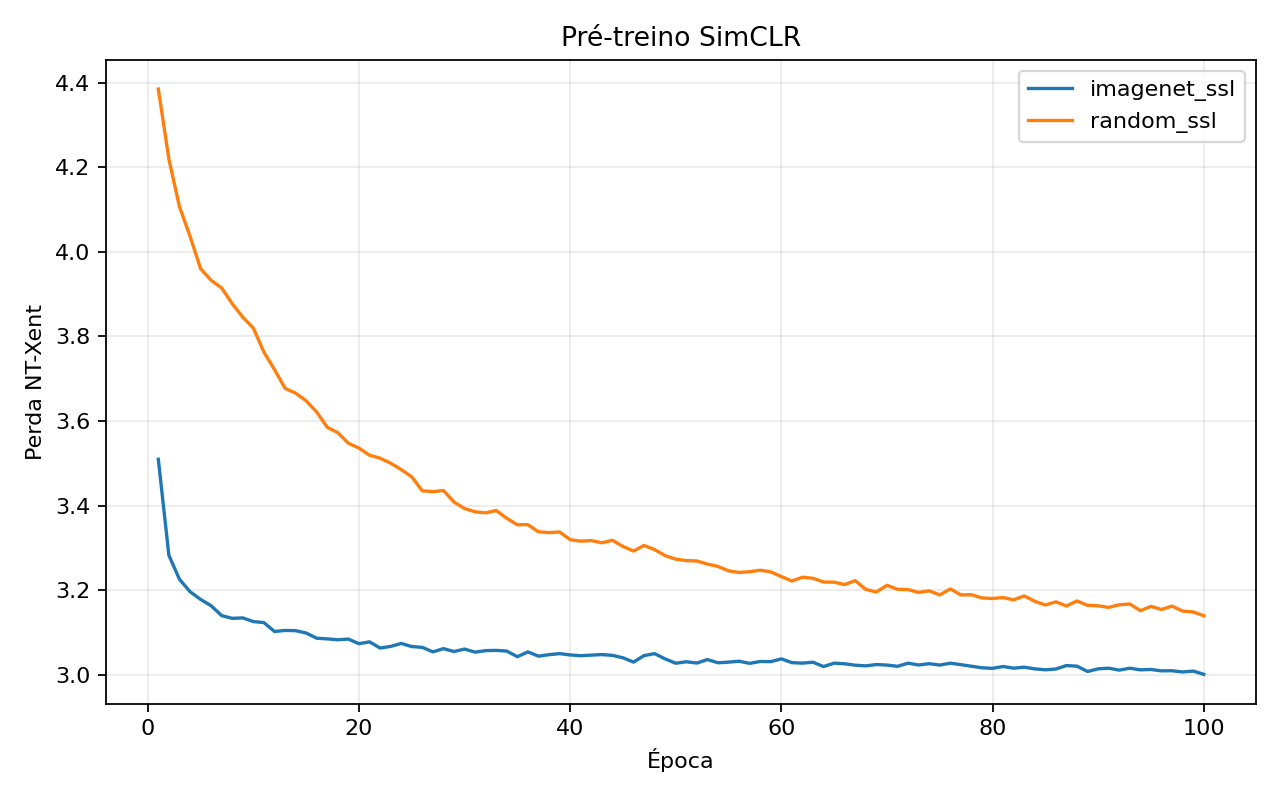

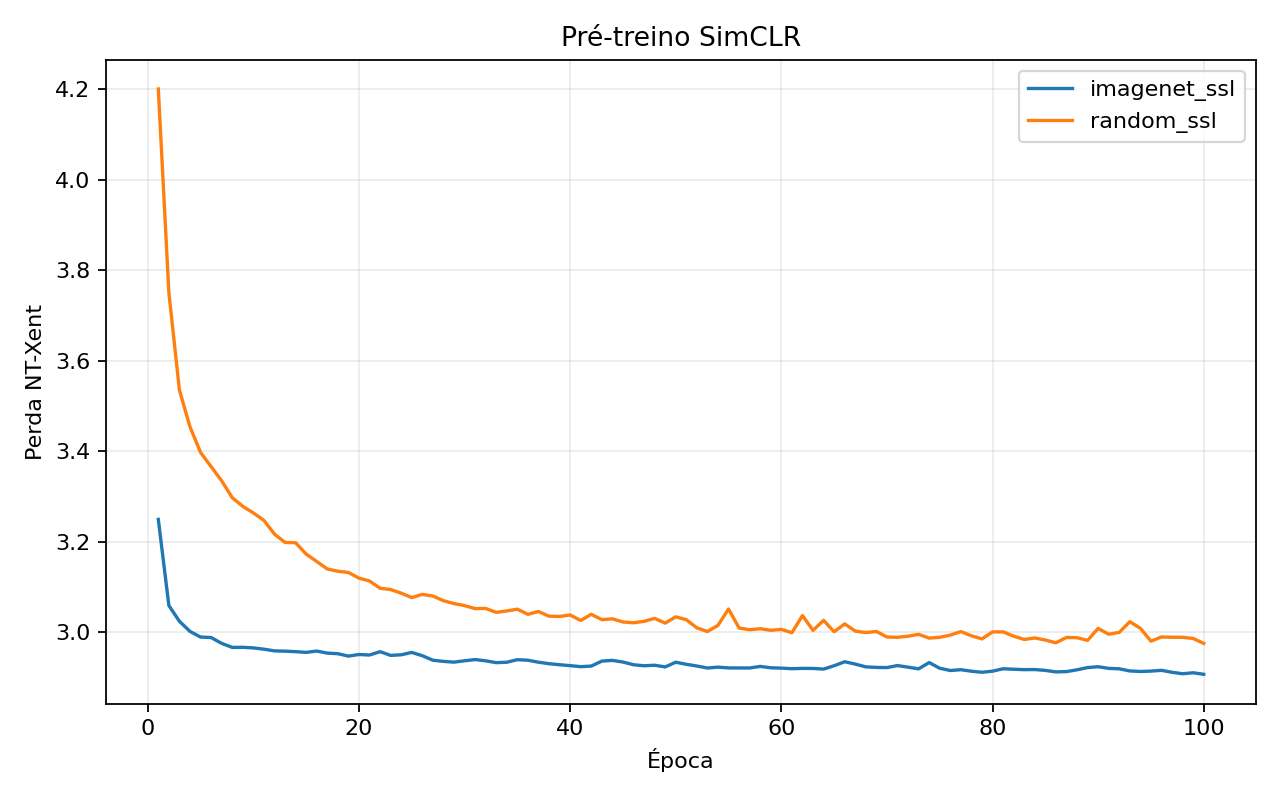

In [12]:
import pandas as pd
from IPython.display import display, Image, FileLink
report = json.loads((OUTPUT / 'relatorio_trilha_a.json').read_text())
table = pd.read_csv(OUTPUT / 'resultados_trilha_a.csv')
display(table)
print('Crop selecionado por validação:', report['selected_augmentation'])
print('Execução preliminar:', report['preliminary'])
linear = table[table.evaluation == 'linear']
display(linear.pivot(index='initialization', columns='augmentation', values='test_public_macro_f1'))
display(pd.DataFrame(report['augmentation_comparison']))
for crop in ['standard', 'context_preserving']:
    display(Image(filename=str(OUTPUT / crop / 'curva_simclr.png')))


## Exportar relatório e checkpoints

O relatório inclui as métricas locais da Parte 0; as figuras dessa parte não estão incorporadas.
O arquivo leve exclui pesos. O arquivo completo inclui checkpoints para retomada.
Se a sessão for interrompida antes desta célula, preserve a pasta de outputs e anexe-a à próxima sessão;
preencha `RESTORE_FROM`. Não dependa de uma sessão ativa como única cópia dos checkpoints.


In [13]:
from gerar_relatorio import make_report
DELIVERY = WORK / 'resultados/entrega_completa'
make_report(WORK / 'resultados', DELIVERY, OUTPUT)
shutil.make_archive('/kaggle/working/pa3_relatorio', 'zip', DELIVERY)
shutil.make_archive('/kaggle/working/pa3_resultados_completos', 'zip', WORK, 'resultados')
display(FileLink('/kaggle/working/pa3_relatorio.zip'))
display(FileLink('/kaggle/working/pa3_resultados_completos.zip'))


/kaggle/working/pa3_relatorio.zip

/kaggle/working/pa3_resultados_completos.zip